# 20nodes_EB_obsconf0_latconf0_NonGaussian_Linear: tuned



In [1]:
from pathlib import Path
import sys, os, json
ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p / "experiments/run_model.py").is_file()), None)
if ROOT is None:
    raise RuntimeError("Open this notebook from inside the repository.")
os.environ.setdefault("MPLCONFIGDIR", str(ROOT / ".cache/matplotlib"))
sys.path[:0] = [str(ROOT / "analysis"), str(ROOT / "experiments")]
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import final_visualization as fv
import result_tables as th
fv.apply_style()
th.ensure_output_dirs("tuned")
from scipy.stats import spearmanr
from varsortability import calculate_varsortability
from condition_data import load_sample, sample_path


def sortability(frame, study):
    rows = []
    for family, seed in (
        frame[["dataset", "dataset_seed"]].drop_duplicates().itertuples(index=False, name=None)
    ):
        path = sample_path({"tuned": "evaluation"}.get(study, study), family)
        with load_sample(study, family, int(seed)) as data:
            raw = "X_raw" in data.files
            result = calculate_varsortability(data["X_raw"] if raw else data["X"], data["true_adj"])
            if not raw:
                for key in (
                    "varsortability",
                    "n_ordered_variance_paths",
                    "n_tied_variance_paths",
                ):
                    result[key] = np.nan
        rows.append(
            dict(
                dataset=family,
                dataset_seed=seed,
                study=study,
                raw_variance_available=raw,
                sample_path=str(path.relative_to(ROOT)),
                **result,
            )
        )
    return pd.DataFrame(rows)


In [2]:


output = ROOT / "results"
output.mkdir(parents=True, exist_ok=True)
sources = th.load_aligned_sources()
main = sources["benchmark_with_biological"]
complete = sources["complete"]
correlations = []
(output / "tuned" / "by_family" / '20nodes_EB_obsconf0_latconf0_NonGaussian_Linear').mkdir(parents=True, exist_ok=True)


## Metrics, seed stability and sortability


,model,mean,std,size
0,AVICI,0.339193,0.121826,15
1,DAGMA_Linear,0.208437,0.063873,15
2,DAGMA_Nonlinear,0.007727,0.021283,15
3,DAS,0.123092,0.063182,15
4,DirectLiNGAM,0.882192,0.063454,15
5,FCI,0.099712,0.052877,15
6,GES,0.398887,0.156171,15
7,GOLEM,0.439028,0.108111,15
8,GRaSP,0.751563,0.125887,15
9,GraNDAG,0.065646,0.056424,15


,model,mean,std,size
0,AVICI,47.533333,8.279637,15
1,DAGMA_Linear,63.733333,8.319226,15
2,DAGMA_Nonlinear,59.000000,7.410803,15
3,DAS,103.066667,13.588160,15
4,DirectLiNGAM,11.933333,6.463819,15
5,FCI,61.666667,8.809951,15
6,GES,75.866667,21.807164,15
7,GOLEM,52.000000,11.704700,15
8,GRaSP,29.000000,17.980307,15
9,GraNDAG,55.800000,6.449806,15


,model,mean,std,size
0,AVICI,0.764308,0.112467,15
1,DAGMA_Linear,0.267002,0.085865,15
2,DAGMA_Nonlinear,0.038540,0.129234,15
3,DAS,0.098488,0.051833,15
4,DirectLiNGAM,1.000000,0.000000,15
5,FCI,0.509449,0.173021,15
6,GES,0.331757,0.158536,15
7,GOLEM,0.448022,0.111408,15
8,GRaSP,0.734471,0.152220,15
9,GraNDAG,0.528889,0.297641,15


,model,mean,std,size
0,AVICI,0.228931,0.110309,15
1,DAGMA_Linear,0.172547,0.052979,15
2,DAGMA_Nonlinear,0.004571,0.012256,15
3,DAS,0.165318,0.082298,15
4,DirectLiNGAM,0.794420,0.098387,15
5,FCI,0.057001,0.033443,15
6,GES,0.509060,0.150643,15
7,GOLEM,0.433995,0.111257,15
8,GRaSP,0.781837,0.094525,15
9,GraNDAG,0.036451,0.034915,15


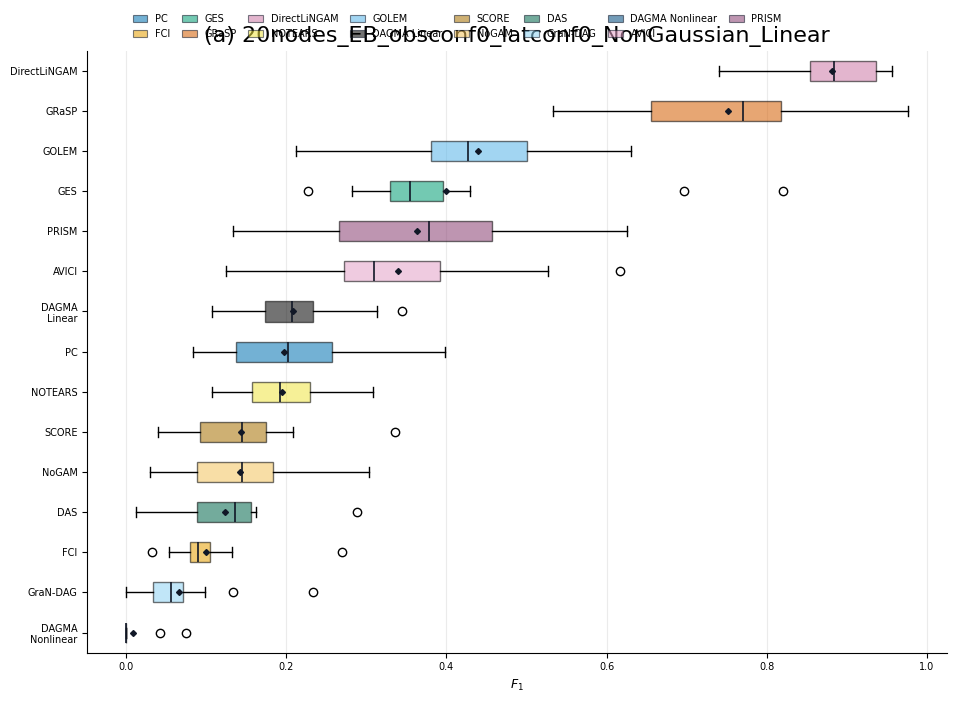

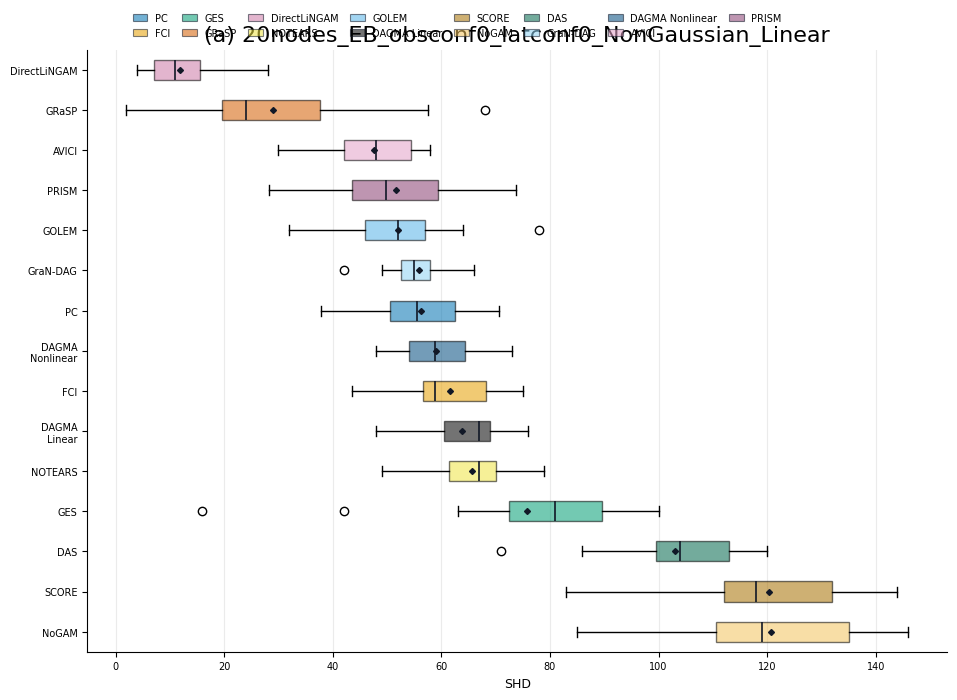

,dataset_seed,model,f1_range
0,19,AVICI,0.000000
1,19,DAGMA_Linear,0.000000
2,19,DAGMA_Nonlinear,0.000000
3,19,DAS,0.000000
4,19,DirectLiNGAM,0.000000
5,19,FCI,0.140015
6,19,GES,0.000000
7,19,GOLEM,0.000000
8,19,GRaSP,0.472685
9,19,GraNDAG,0.000000


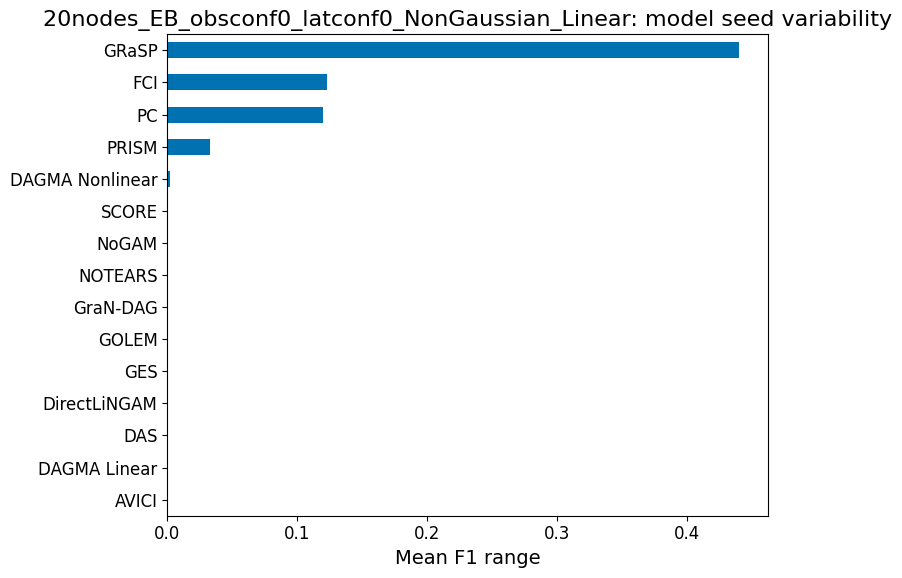

,model_seed,model,f1_range
0,0,AVICI,0.492284
1,0,DAGMA_Linear,0.237703
2,0,DAGMA_Nonlinear,0.074074
3,0,DAS,0.275805
4,0,DirectLiNGAM,0.215781
5,0,FCI,0.295082
6,0,GES,0.593333
7,0,GOLEM,0.419249
8,0,GRaSP,0.525180
9,0,GraNDAG,0.233333


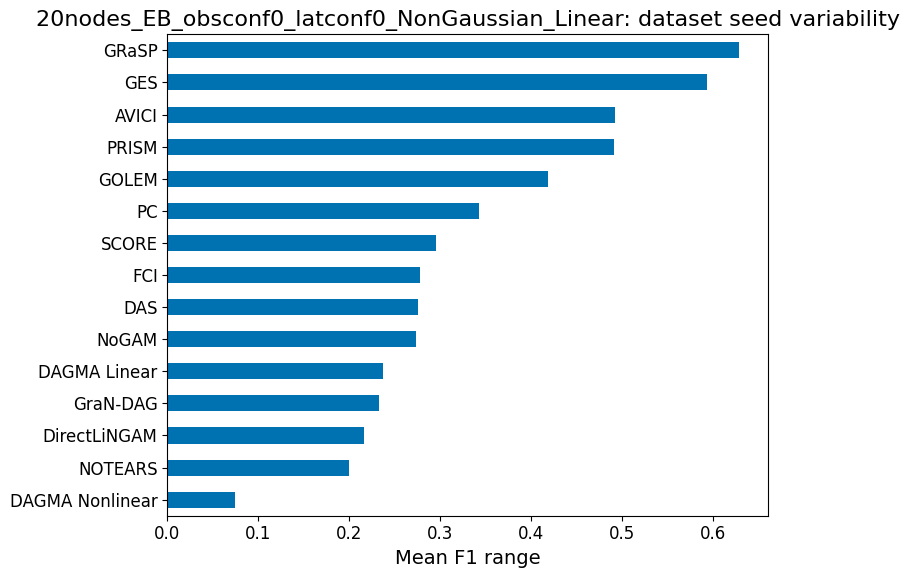

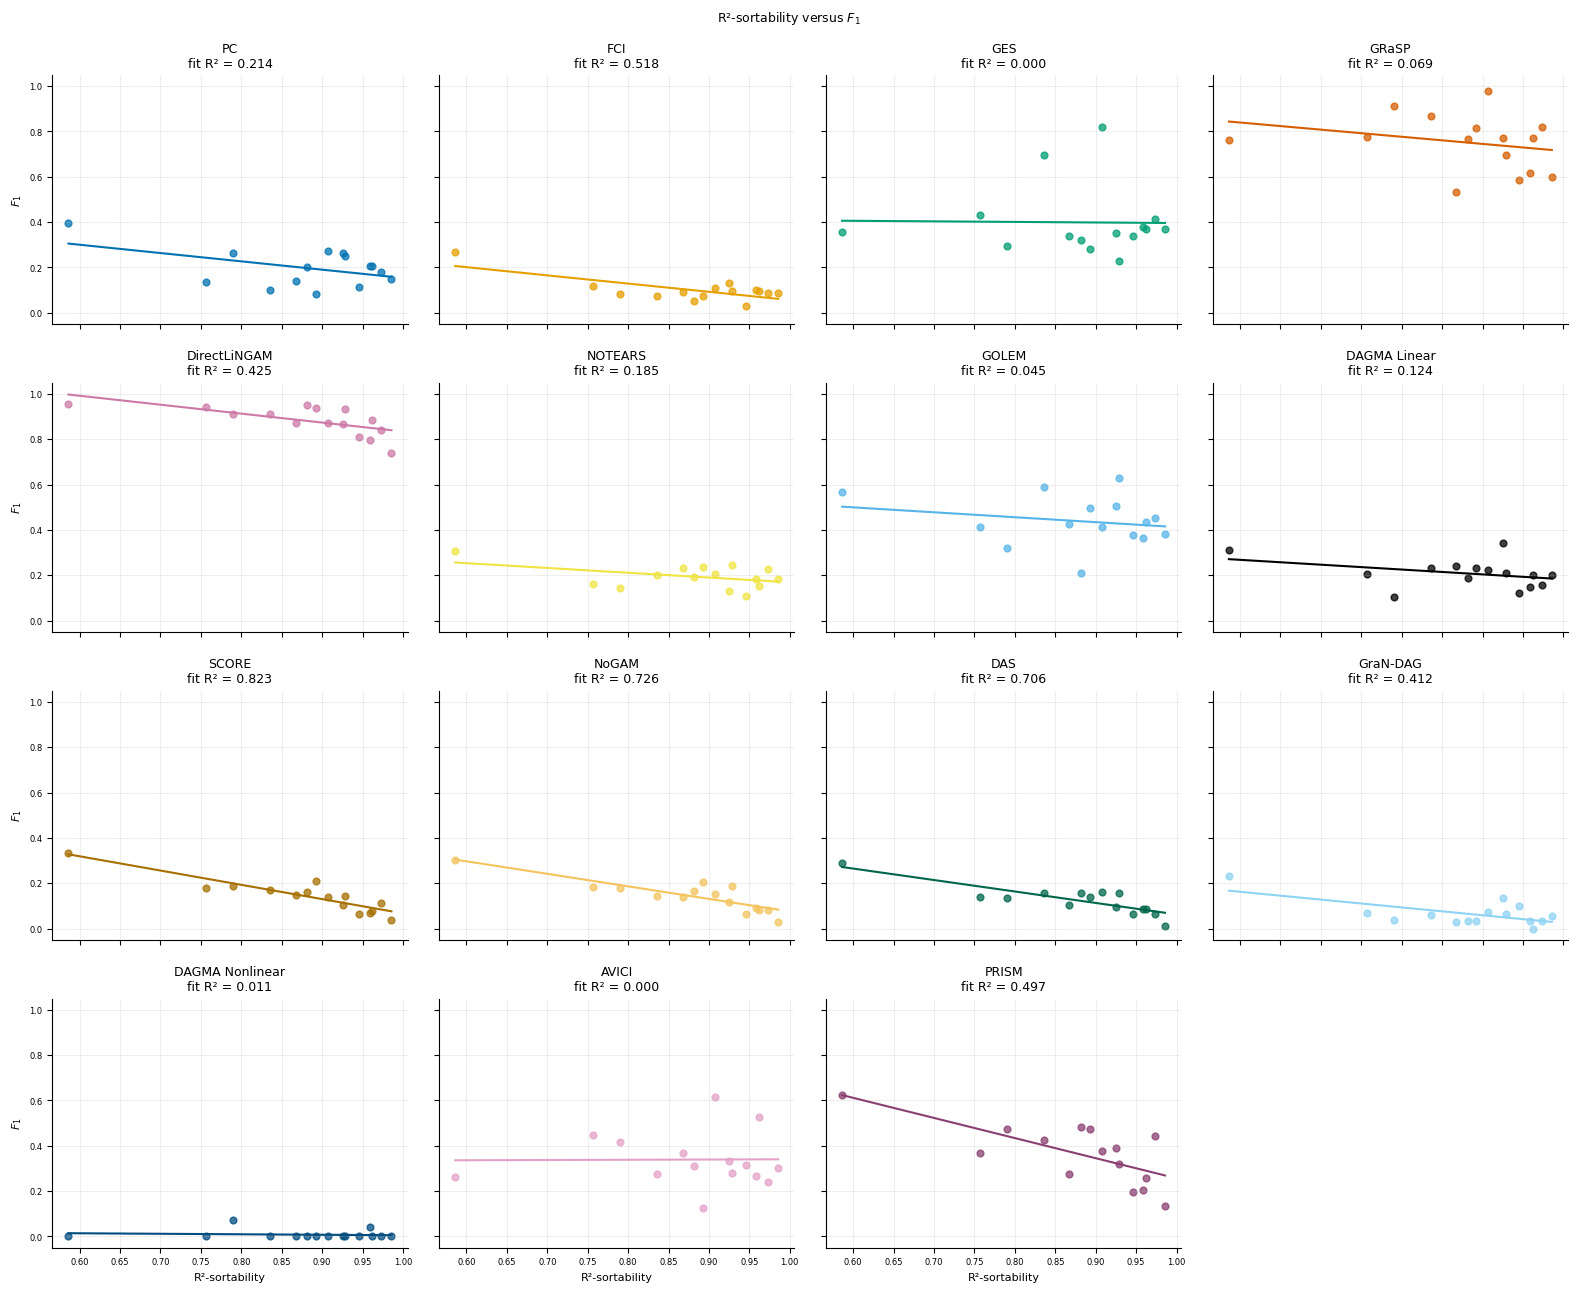

,dataset_seed,dataset,model,metric_value,completed_model_seeds,n_nodes,graph_type,obs_conf,lat_conf,noise,...,sample_path,varsortability,r2_sortability,n_paths,n_ordered_variance_paths,n_tied_variance_paths,n_ordered_r2_paths,n_tied_r2_paths,n_variables,n_observations
0,19,20nodes_EB_obsconf0_latconf0_NonGaussian_Linear,AVICI,0.281690,5,20,EB,0,0,NonGaussian,...,datasets/tuned/20nodes_EB_obsconf0_latconf0_No...,0.979592,0.928571,294,288,0,273,0,20,2000
1,19,20nodes_EB_obsconf0_latconf0_NonGaussian_Linear,DAGMA_Linear,0.209524,5,20,EB,0,0,NonGaussian,...,datasets/tuned/20nodes_EB_obsconf0_latconf0_No...,0.979592,0.928571,294,288,0,273,0,20,2000
2,19,20nodes_EB_obsconf0_latconf0_NonGaussian_Linear,DAGMA_Nonlinear,0.000000,5,20,EB,0,0,NonGaussian,...,datasets/tuned/20nodes_EB_obsconf0_latconf0_No...,0.979592,0.928571,294,288,0,273,0,20,2000
3,19,20nodes_EB_obsconf0_latconf0_NonGaussian_Linear,DAS,0.158273,5,20,EB,0,0,NonGaussian,...,datasets/tuned/20nodes_EB_obsconf0_latconf0_No...,0.979592,0.928571,294,288,0,273,0,20,2000
4,19,20nodes_EB_obsconf0_latconf0_NonGaussian_Linear,DirectLiNGAM,0.935780,5,20,EB,0,0,NonGaussian,...,datasets/tuned/20nodes_EB_obsconf0_latconf0_No...,0.979592,0.928571,294,288,0,273,0,20,2000
5,19,20nodes_EB_obsconf0_latconf0_NonGaussian_Linear,FCI,0.095471,5,20,EB,0,0,NonGaussian,...,datasets/tuned/20nodes_EB_obsconf0_latconf0_No...,0.979592,0.928571,294,288,0,273,0,20,2000
6,19,20nodes_EB_obsconf0_latconf0_NonGaussian_Linear,GES,0.226667,5,20,EB,0,0,NonGaussian,...,datasets/tuned/20nodes_EB_obsconf0_latconf0_No...,0.979592,0.928571,294,288,0,273,0,20,2000
7,19,20nodes_EB_obsconf0_latconf0_NonGaussian_Linear,GOLEM,0.630631,5,20,EB,0,0,NonGaussian,...,datasets/tuned/20nodes_EB_obsconf0_latconf0_No...,0.979592,0.928571,294,288,0,273,0,20,2000
8,19,20nodes_EB_obsconf0_latconf0_NonGaussian_Linear,GRaSP,0.694078,5,20,EB,0,0,NonGaussian,...,datasets/tuned/20nodes_EB_obsconf0_latconf0_No...,0.979592,0.928571,294,288,0,273,0,20,2000
9,19,20nodes_EB_obsconf0_latconf0_NonGaussian_Linear,GraNDAG,0.064516,5,20,EB,0,0,NonGaussian,...,datasets/tuned/20nodes_EB_obsconf0_latconf0_No...,0.979592,0.928571,294,288,0,273,0,20,2000


,dataset,dataset_seed,study,raw_variance_available,sample_path,varsortability,r2_sortability,n_paths,n_ordered_variance_paths,n_tied_variance_paths,n_ordered_r2_paths,n_tied_r2_paths,n_variables,n_observations
0,20nodes_EB_obsconf0_latconf0_NonGaussian_Linear,19,tuned,True,datasets/tuned/20nodes_EB_obsconf0_latconf0_No...,0.979592,0.928571,294,288,0,273,0,20,2000
1,20nodes_EB_obsconf0_latconf0_NonGaussian_Linear,47,tuned,True,datasets/tuned/20nodes_EB_obsconf0_latconf0_No...,0.984906,0.962264,265,261,0,255,0,20,2000
2,20nodes_EB_obsconf0_latconf0_NonGaussian_Linear,50,tuned,True,datasets/tuned/20nodes_EB_obsconf0_latconf0_No...,0.955774,0.867322,407,389,0,353,0,20,2000
3,20nodes_EB_obsconf0_latconf0_NonGaussian_Linear,52,tuned,True,datasets/tuned/20nodes_EB_obsconf0_latconf0_No...,0.988281,0.835938,256,253,0,214,0,20,2000
4,20nodes_EB_obsconf0_latconf0_NonGaussian_Linear,71,tuned,True,datasets/tuned/20nodes_EB_obsconf0_latconf0_No...,0.983264,0.945607,239,235,0,226,0,20,2000
5,20nodes_EB_obsconf0_latconf0_NonGaussian_Linear,75,tuned,True,datasets/tuned/20nodes_EB_obsconf0_latconf0_No...,0.943343,0.892351,353,333,0,315,0,20,2000
6,20nodes_EB_obsconf0_latconf0_NonGaussian_Linear,77,tuned,True,datasets/tuned/20nodes_EB_obsconf0_latconf0_No...,0.933798,0.881533,287,268,0,253,0,20,2000
7,20nodes_EB_obsconf0_latconf0_NonGaussian_Linear,102,tuned,True,datasets/tuned/20nodes_EB_obsconf0_latconf0_No...,0.996139,0.972973,259,258,0,252,0,20,2000
8,20nodes_EB_obsconf0_latconf0_NonGaussian_Linear,125,tuned,True,datasets/tuned/20nodes_EB_obsconf0_latconf0_No...,0.910345,0.586207,145,132,0,85,0,20,2000
9,20nodes_EB_obsconf0_latconf0_NonGaussian_Linear,158,tuned,True,datasets/tuned/20nodes_EB_obsconf0_latconf0_No...,0.963731,0.756477,193,186,0,146,0,20,2000


""


,model,n_datasets,pearson_r,fit_r_squared,slope,intercept,p_value,spearman_rho,spearman_p_value
0,AVICI,15,0.009210,0.000085,0.010691,0.329788,0.974014,-0.117857,0.675712
1,DAGMA_Linear,15,-0.351818,0.123776,-0.214118,0.396808,0.198455,-0.364286,0.181910
2,DAGMA_Nonlinear,15,-0.107145,0.011480,-0.021728,0.026842,0.703896,-0.072442,0.797517
3,DAS,15,-0.839962,0.705536,-0.505676,0.567962,0.000089,-0.713137,0.002839
4,DirectLiNGAM,15,-0.651992,0.425094,-0.394206,1.228996,0.008441,-0.767857,0.000829
5,FCI,15,-0.720041,0.518459,-0.362777,0.418866,0.002468,-0.160714,0.567197
6,GES,15,-0.016483,0.000272,-0.024528,0.420466,0.953507,0.100000,0.722897
7,GOLEM,15,-0.211381,0.044682,-0.217748,0.630592,0.449494,-0.107143,0.703901
8,GRaSP,15,-0.262286,0.068794,-0.314611,1.028343,0.344975,-0.278571,0.314709
9,GraNDAG,15,-0.641914,0.412053,-0.345110,0.369257,0.009883,-0.296429,0.283355


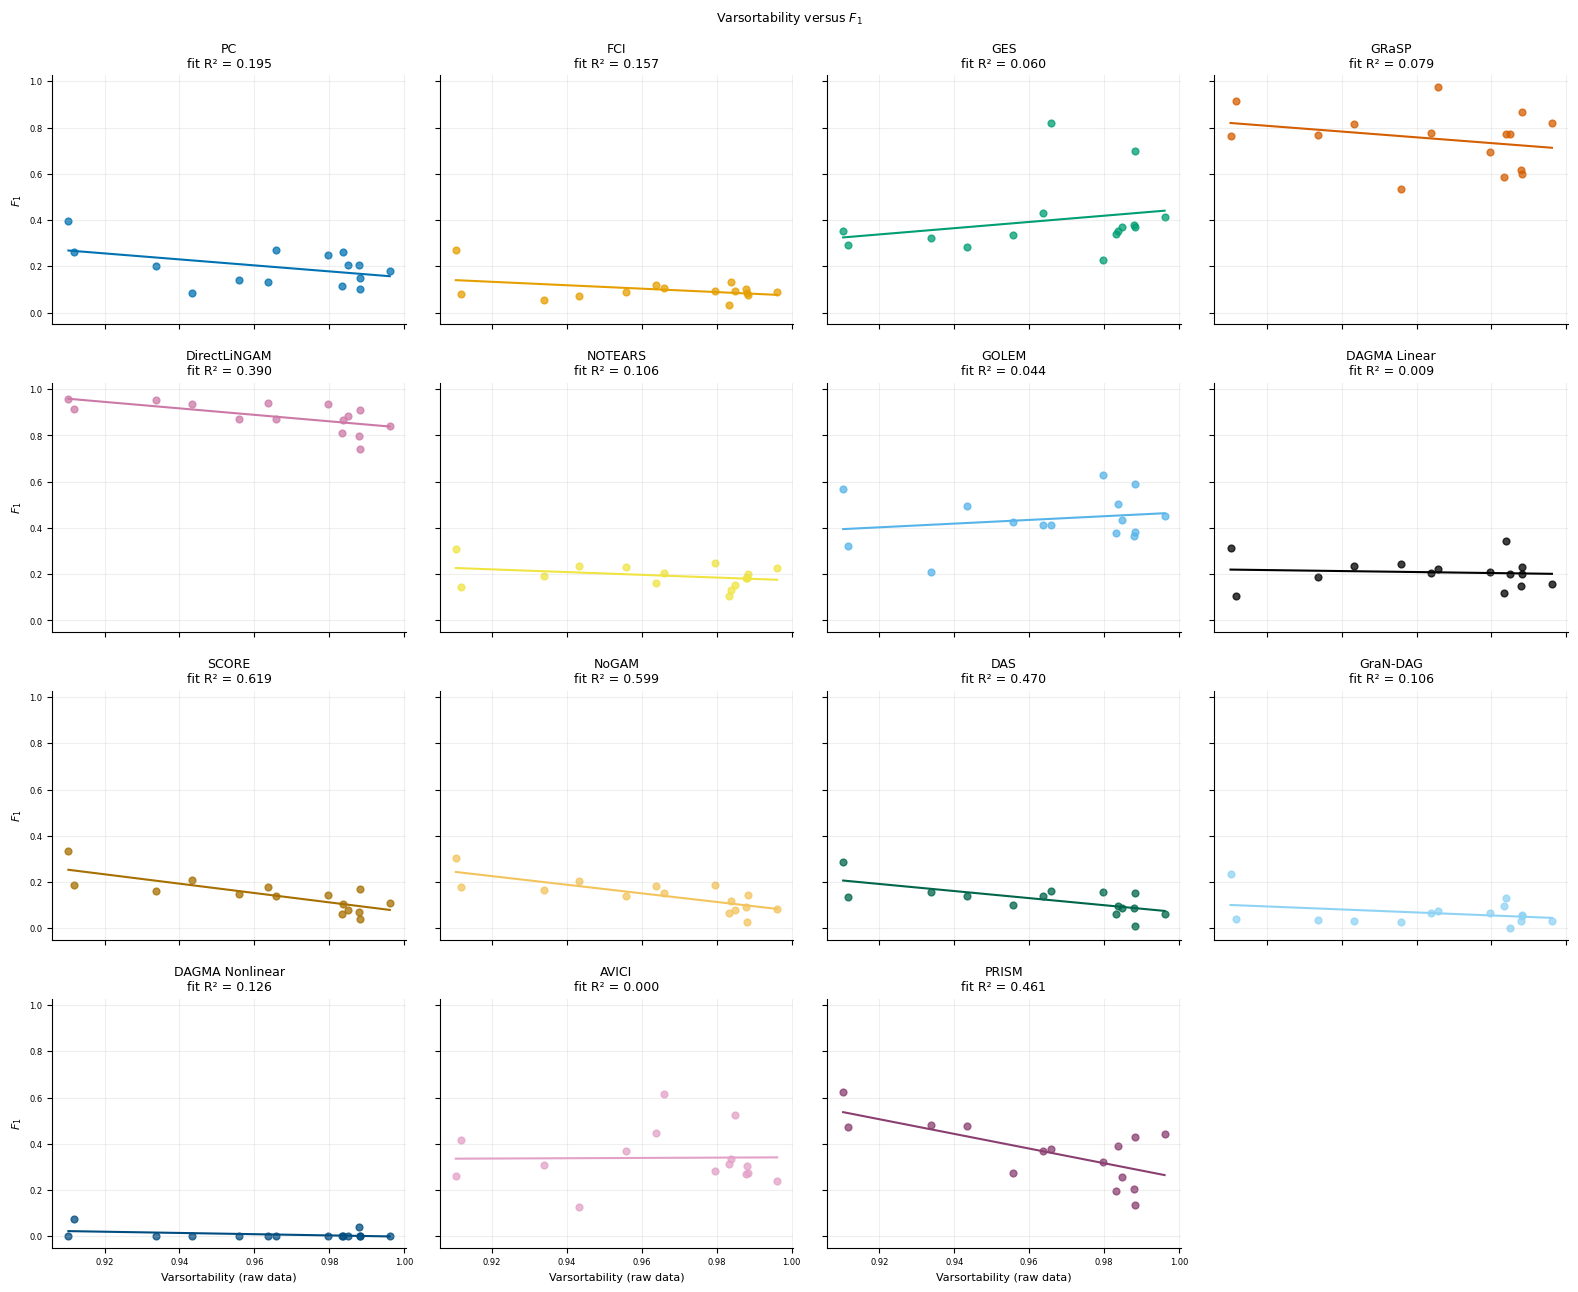

,dataset_seed,dataset,model,metric_value,completed_model_seeds,n_nodes,graph_type,obs_conf,lat_conf,noise,...,sample_path,varsortability,r2_sortability,n_paths,n_ordered_variance_paths,n_tied_variance_paths,n_ordered_r2_paths,n_tied_r2_paths,n_variables,n_observations
0,19,20nodes_EB_obsconf0_latconf0_NonGaussian_Linear,AVICI,0.281690,5,20,EB,0,0,NonGaussian,...,datasets/tuned/20nodes_EB_obsconf0_latconf0_No...,0.979592,0.928571,294,288,0,273,0,20,2000
1,19,20nodes_EB_obsconf0_latconf0_NonGaussian_Linear,DAGMA_Linear,0.209524,5,20,EB,0,0,NonGaussian,...,datasets/tuned/20nodes_EB_obsconf0_latconf0_No...,0.979592,0.928571,294,288,0,273,0,20,2000
2,19,20nodes_EB_obsconf0_latconf0_NonGaussian_Linear,DAGMA_Nonlinear,0.000000,5,20,EB,0,0,NonGaussian,...,datasets/tuned/20nodes_EB_obsconf0_latconf0_No...,0.979592,0.928571,294,288,0,273,0,20,2000
3,19,20nodes_EB_obsconf0_latconf0_NonGaussian_Linear,DAS,0.158273,5,20,EB,0,0,NonGaussian,...,datasets/tuned/20nodes_EB_obsconf0_latconf0_No...,0.979592,0.928571,294,288,0,273,0,20,2000
4,19,20nodes_EB_obsconf0_latconf0_NonGaussian_Linear,DirectLiNGAM,0.935780,5,20,EB,0,0,NonGaussian,...,datasets/tuned/20nodes_EB_obsconf0_latconf0_No...,0.979592,0.928571,294,288,0,273,0,20,2000
5,19,20nodes_EB_obsconf0_latconf0_NonGaussian_Linear,FCI,0.095471,5,20,EB,0,0,NonGaussian,...,datasets/tuned/20nodes_EB_obsconf0_latconf0_No...,0.979592,0.928571,294,288,0,273,0,20,2000
6,19,20nodes_EB_obsconf0_latconf0_NonGaussian_Linear,GES,0.226667,5,20,EB,0,0,NonGaussian,...,datasets/tuned/20nodes_EB_obsconf0_latconf0_No...,0.979592,0.928571,294,288,0,273,0,20,2000
7,19,20nodes_EB_obsconf0_latconf0_NonGaussian_Linear,GOLEM,0.630631,5,20,EB,0,0,NonGaussian,...,datasets/tuned/20nodes_EB_obsconf0_latconf0_No...,0.979592,0.928571,294,288,0,273,0,20,2000
8,19,20nodes_EB_obsconf0_latconf0_NonGaussian_Linear,GRaSP,0.694078,5,20,EB,0,0,NonGaussian,...,datasets/tuned/20nodes_EB_obsconf0_latconf0_No...,0.979592,0.928571,294,288,0,273,0,20,2000
9,19,20nodes_EB_obsconf0_latconf0_NonGaussian_Linear,GraNDAG,0.064516,5,20,EB,0,0,NonGaussian,...,datasets/tuned/20nodes_EB_obsconf0_latconf0_No...,0.979592,0.928571,294,288,0,273,0,20,2000


,dataset,dataset_seed,study,raw_variance_available,sample_path,varsortability,r2_sortability,n_paths,n_ordered_variance_paths,n_tied_variance_paths,n_ordered_r2_paths,n_tied_r2_paths,n_variables,n_observations
0,20nodes_EB_obsconf0_latconf0_NonGaussian_Linear,19,tuned,True,datasets/tuned/20nodes_EB_obsconf0_latconf0_No...,0.979592,0.928571,294,288,0,273,0,20,2000
1,20nodes_EB_obsconf0_latconf0_NonGaussian_Linear,47,tuned,True,datasets/tuned/20nodes_EB_obsconf0_latconf0_No...,0.984906,0.962264,265,261,0,255,0,20,2000
2,20nodes_EB_obsconf0_latconf0_NonGaussian_Linear,50,tuned,True,datasets/tuned/20nodes_EB_obsconf0_latconf0_No...,0.955774,0.867322,407,389,0,353,0,20,2000
3,20nodes_EB_obsconf0_latconf0_NonGaussian_Linear,52,tuned,True,datasets/tuned/20nodes_EB_obsconf0_latconf0_No...,0.988281,0.835938,256,253,0,214,0,20,2000
4,20nodes_EB_obsconf0_latconf0_NonGaussian_Linear,71,tuned,True,datasets/tuned/20nodes_EB_obsconf0_latconf0_No...,0.983264,0.945607,239,235,0,226,0,20,2000
5,20nodes_EB_obsconf0_latconf0_NonGaussian_Linear,75,tuned,True,datasets/tuned/20nodes_EB_obsconf0_latconf0_No...,0.943343,0.892351,353,333,0,315,0,20,2000
6,20nodes_EB_obsconf0_latconf0_NonGaussian_Linear,77,tuned,True,datasets/tuned/20nodes_EB_obsconf0_latconf0_No...,0.933798,0.881533,287,268,0,253,0,20,2000
7,20nodes_EB_obsconf0_latconf0_NonGaussian_Linear,102,tuned,True,datasets/tuned/20nodes_EB_obsconf0_latconf0_No...,0.996139,0.972973,259,258,0,252,0,20,2000
8,20nodes_EB_obsconf0_latconf0_NonGaussian_Linear,125,tuned,True,datasets/tuned/20nodes_EB_obsconf0_latconf0_No...,0.910345,0.586207,145,132,0,85,0,20,2000
9,20nodes_EB_obsconf0_latconf0_NonGaussian_Linear,158,tuned,True,datasets/tuned/20nodes_EB_obsconf0_latconf0_No...,0.963731,0.756477,193,186,0,146,0,20,2000


""


,model,n_datasets,pearson_r,fit_r_squared,slope,intercept,p_value,spearman_rho,spearman_p_value
0,AVICI,15,0.015350,0.000236,0.066071,0.275428,0.956700,-0.160714,0.567197
1,DAGMA_Linear,15,-0.094706,0.008969,-0.213726,0.414705,0.737074,-0.182143,0.515882
2,DAGMA_Nonlinear,15,-0.355601,0.126452,-0.267393,0.265789,0.193336,-0.120736,0.668202
3,DAS,15,-0.685656,0.470124,-1.530600,1.600278,0.004777,-0.595175,0.019249
4,DirectLiNGAM,15,-0.624445,0.389931,-1.399967,2.233304,0.012831,-0.728571,0.002065
5,FCI,15,-0.396732,0.157396,-0.741179,0.815026,0.143160,-0.057143,0.839700
6,GES,15,0.244192,0.059630,1.347398,-0.901490,0.380436,0.539286,0.038022
7,GOLEM,15,0.209342,0.043824,0.799626,-0.332694,0.453981,0.178571,0.524284
8,GRaSP,15,-0.280750,0.078821,-1.248711,1.956698,0.310781,-0.021429,0.939578
9,GraNDAG,15,-0.325866,0.106189,-0.649626,0.692601,0.235905,-0.142857,0.611522


,model,mean,std,size
0,AVICI,0.482577,0.084497,15
1,DAGMA_Linear,0.188525,0.068492,15
2,DAGMA_Nonlinear,0.127432,0.066428,15
3,DAS,0.126296,0.073666,15
4,DirectLiNGAM,0.998139,0.003858,15
5,FCI,0.077795,0.066444,15
6,GES,0.402813,0.155557,15
7,GOLEM,0.159762,0.089777,15
8,GRaSP,0.751563,0.125887,15
9,GraNDAG,0.050994,0.042311,15


,model,mean,std,size
0,AVICI,53.733333,10.819735,15
1,DAGMA_Linear,60.066667,8.163216,15
2,DAGMA_Nonlinear,66.280000,9.871402,15
3,DAS,101.933333,17.314184,15
4,DirectLiNGAM,0.200000,0.414039,15
5,FCI,60.066667,7.657552,15
6,GES,85.533333,26.877677,15
7,GOLEM,79.933333,12.969561,15
8,GRaSP,29.000000,17.980307,15
9,GraNDAG,55.866667,5.914470,15


,model,mean,std,size
0,AVICI,0.510256,0.095017,15
1,DAGMA_Linear,0.263478,0.095029,15
2,DAGMA_Nonlinear,0.178441,0.097453,15
3,DAS,0.101869,0.062793,15
4,DirectLiNGAM,0.996312,0.007645,15
5,FCI,0.428704,0.290316,15
6,GES,0.317418,0.159208,15
7,GOLEM,0.149599,0.082082,15
8,GRaSP,0.734471,0.152220,15
9,GraNDAG,0.360556,0.305926,15


,model,mean,std,size
0,AVICI,0.464324,0.094043,15
1,DAGMA_Linear,0.148210,0.056385,15
2,DAGMA_Nonlinear,0.103053,0.056235,15
3,DAS,0.168057,0.090894,15
4,DirectLiNGAM,1.000000,0.000000,15
5,FCI,0.043740,0.039186,15
6,GES,0.568495,0.136288,15
7,GOLEM,0.172375,0.100206,15
8,GRaSP,0.781837,0.094525,15
9,GraNDAG,0.028765,0.025599,15


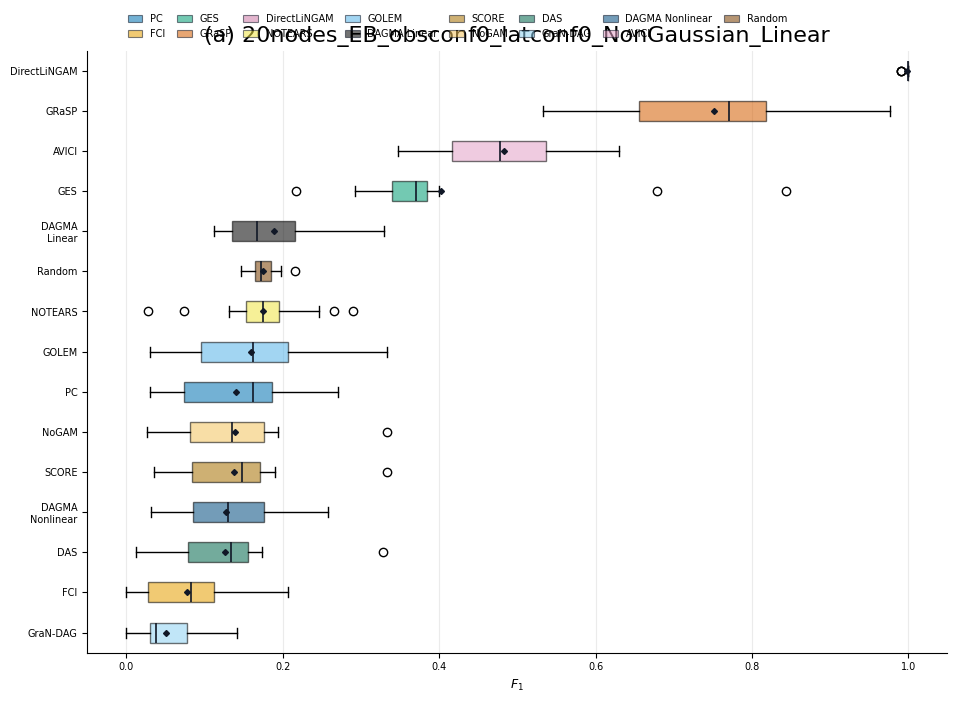

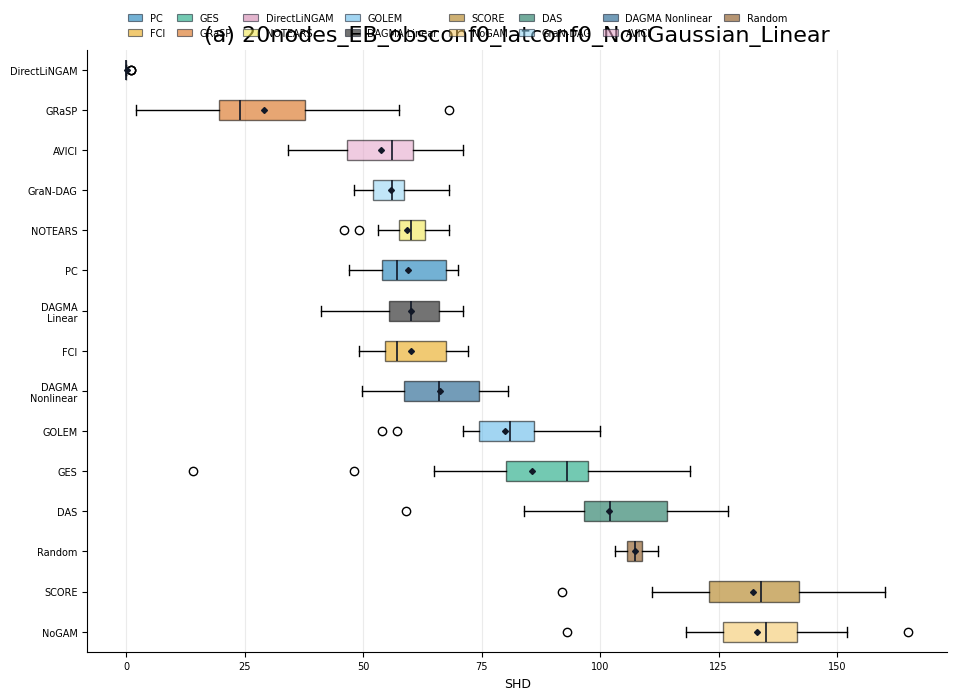

,dataset_seed,model,f1_range
0,19,AVICI,0.000000
1,19,DAGMA_Linear,0.000000
2,19,DAGMA_Nonlinear,0.146199
3,19,DAS,0.000000
4,19,DirectLiNGAM,0.000000
5,19,FCI,0.000000
6,19,GES,0.000000
7,19,GOLEM,0.000000
8,19,GRaSP,0.472685
9,19,GraNDAG,0.000000


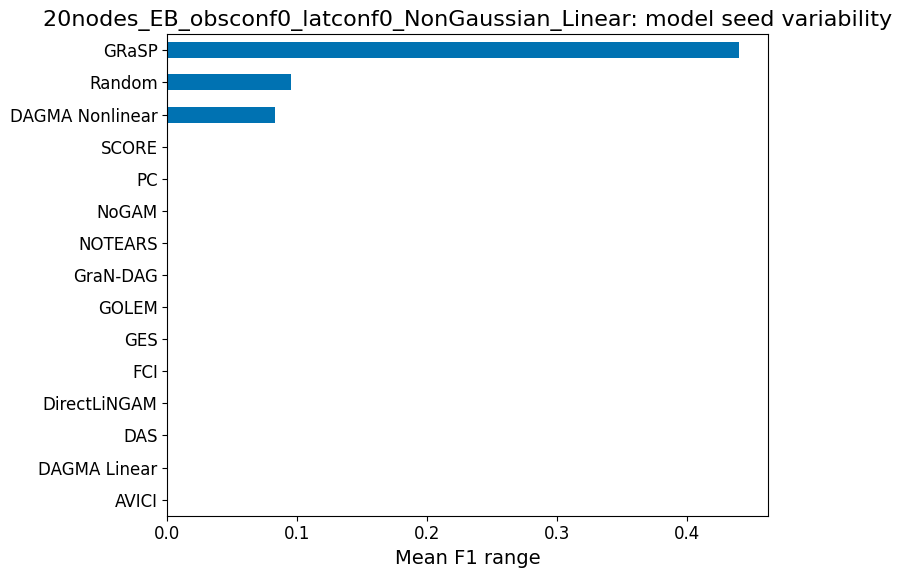

,model_seed,model,f1_range
0,0,AVICI,0.282805
1,0,DAGMA_Linear,0.216754
2,0,DAGMA_Nonlinear,0.220915
3,0,DAS,0.315681
4,0,DirectLiNGAM,0.009901
5,0,FCI,0.206897
6,0,GES,0.625746
7,0,GOLEM,0.302799
8,0,GRaSP,0.525180
9,0,GraNDAG,0.140845


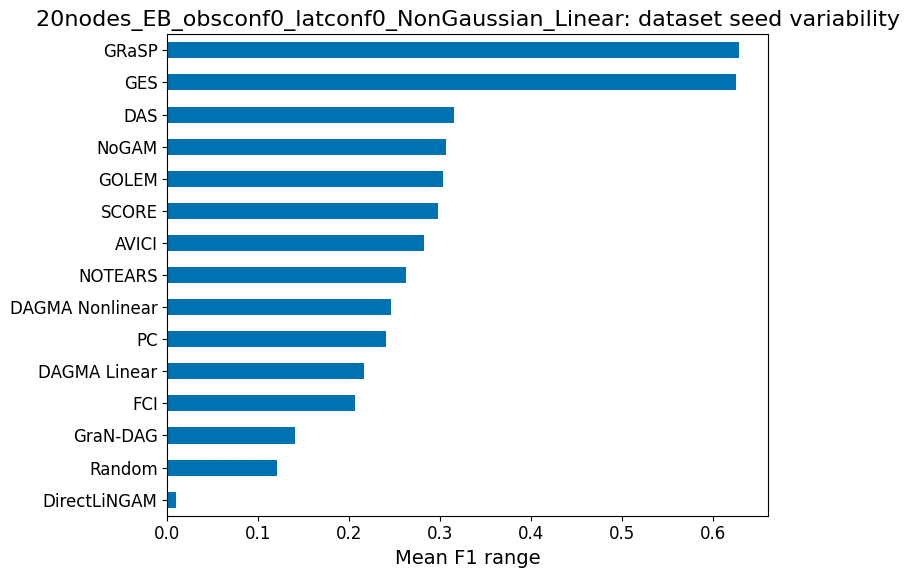

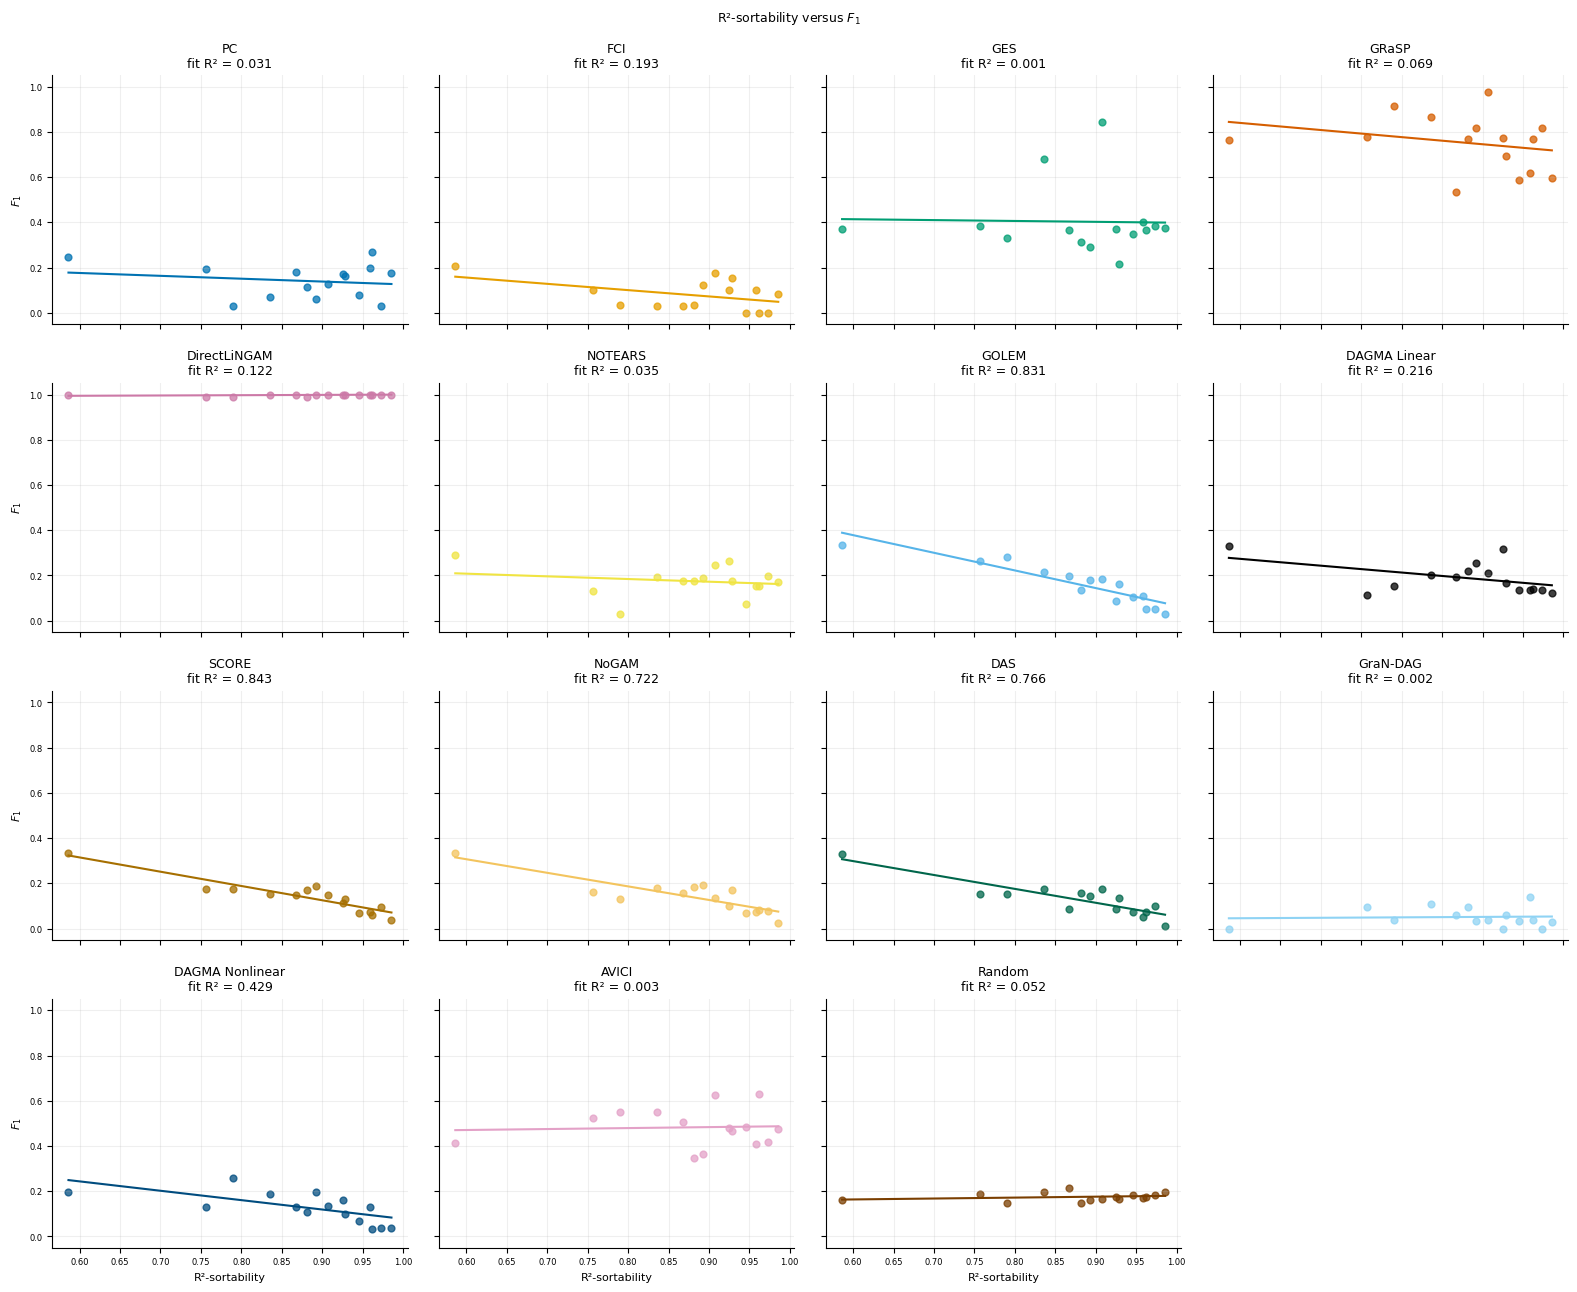

,dataset_seed,dataset,model,metric_value,completed_model_seeds,n_nodes,graph_type,obs_conf,lat_conf,noise,...,sample_path,varsortability,r2_sortability,n_paths,n_ordered_variance_paths,n_tied_variance_paths,n_ordered_r2_paths,n_tied_r2_paths,n_variables,n_observations
0,19,20nodes_EB_obsconf0_latconf0_NonGaussian_Linear,AVICI,0.464286,5,20,EB,0,0,NonGaussian,...,datasets/tuned/20nodes_EB_obsconf0_latconf0_No...,0.979592,0.928571,294,288,0,273,0,20,2000
1,19,20nodes_EB_obsconf0_latconf0_NonGaussian_Linear,DAGMA_Linear,0.166667,5,20,EB,0,0,NonGaussian,...,datasets/tuned/20nodes_EB_obsconf0_latconf0_No...,0.979592,0.928571,294,288,0,273,0,20,2000
2,19,20nodes_EB_obsconf0_latconf0_NonGaussian_Linear,DAGMA_Nonlinear,0.100520,5,20,EB,0,0,NonGaussian,...,datasets/tuned/20nodes_EB_obsconf0_latconf0_No...,0.979592,0.928571,294,288,0,273,0,20,2000
3,19,20nodes_EB_obsconf0_latconf0_NonGaussian_Linear,DAS,0.133333,5,20,EB,0,0,NonGaussian,...,datasets/tuned/20nodes_EB_obsconf0_latconf0_No...,0.979592,0.928571,294,288,0,273,0,20,2000
4,19,20nodes_EB_obsconf0_latconf0_NonGaussian_Linear,DirectLiNGAM,1.000000,5,20,EB,0,0,NonGaussian,...,datasets/tuned/20nodes_EB_obsconf0_latconf0_No...,0.979592,0.928571,294,288,0,273,0,20,2000
5,19,20nodes_EB_obsconf0_latconf0_NonGaussian_Linear,FCI,0.151515,5,20,EB,0,0,NonGaussian,...,datasets/tuned/20nodes_EB_obsconf0_latconf0_No...,0.979592,0.928571,294,288,0,273,0,20,2000
6,19,20nodes_EB_obsconf0_latconf0_NonGaussian_Linear,GES,0.217391,5,20,EB,0,0,NonGaussian,...,datasets/tuned/20nodes_EB_obsconf0_latconf0_No...,0.979592,0.928571,294,288,0,273,0,20,2000
7,19,20nodes_EB_obsconf0_latconf0_NonGaussian_Linear,GOLEM,0.161290,5,20,EB,0,0,NonGaussian,...,datasets/tuned/20nodes_EB_obsconf0_latconf0_No...,0.979592,0.928571,294,288,0,273,0,20,2000
8,19,20nodes_EB_obsconf0_latconf0_NonGaussian_Linear,GRaSP,0.694078,5,20,EB,0,0,NonGaussian,...,datasets/tuned/20nodes_EB_obsconf0_latconf0_No...,0.979592,0.928571,294,288,0,273,0,20,2000
9,19,20nodes_EB_obsconf0_latconf0_NonGaussian_Linear,GraNDAG,0.058824,5,20,EB,0,0,NonGaussian,...,datasets/tuned/20nodes_EB_obsconf0_latconf0_No...,0.979592,0.928571,294,288,0,273,0,20,2000


,dataset,dataset_seed,study,raw_variance_available,sample_path,varsortability,r2_sortability,n_paths,n_ordered_variance_paths,n_tied_variance_paths,n_ordered_r2_paths,n_tied_r2_paths,n_variables,n_observations
0,20nodes_EB_obsconf0_latconf0_NonGaussian_Linear,19,tuned,True,datasets/tuned/20nodes_EB_obsconf0_latconf0_No...,0.979592,0.928571,294,288,0,273,0,20,2000
1,20nodes_EB_obsconf0_latconf0_NonGaussian_Linear,47,tuned,True,datasets/tuned/20nodes_EB_obsconf0_latconf0_No...,0.984906,0.962264,265,261,0,255,0,20,2000
2,20nodes_EB_obsconf0_latconf0_NonGaussian_Linear,50,tuned,True,datasets/tuned/20nodes_EB_obsconf0_latconf0_No...,0.955774,0.867322,407,389,0,353,0,20,2000
3,20nodes_EB_obsconf0_latconf0_NonGaussian_Linear,52,tuned,True,datasets/tuned/20nodes_EB_obsconf0_latconf0_No...,0.988281,0.835938,256,253,0,214,0,20,2000
4,20nodes_EB_obsconf0_latconf0_NonGaussian_Linear,71,tuned,True,datasets/tuned/20nodes_EB_obsconf0_latconf0_No...,0.983264,0.945607,239,235,0,226,0,20,2000
5,20nodes_EB_obsconf0_latconf0_NonGaussian_Linear,75,tuned,True,datasets/tuned/20nodes_EB_obsconf0_latconf0_No...,0.943343,0.892351,353,333,0,315,0,20,2000
6,20nodes_EB_obsconf0_latconf0_NonGaussian_Linear,77,tuned,True,datasets/tuned/20nodes_EB_obsconf0_latconf0_No...,0.933798,0.881533,287,268,0,253,0,20,2000
7,20nodes_EB_obsconf0_latconf0_NonGaussian_Linear,102,tuned,True,datasets/tuned/20nodes_EB_obsconf0_latconf0_No...,0.996139,0.972973,259,258,0,252,0,20,2000
8,20nodes_EB_obsconf0_latconf0_NonGaussian_Linear,125,tuned,True,datasets/tuned/20nodes_EB_obsconf0_latconf0_No...,0.910345,0.586207,145,132,0,85,0,20,2000
9,20nodes_EB_obsconf0_latconf0_NonGaussian_Linear,158,tuned,True,datasets/tuned/20nodes_EB_obsconf0_latconf0_No...,0.963731,0.756477,193,186,0,146,0,20,2000


""


,model,n_datasets,pearson_r,fit_r_squared,slope,intercept,p_value,spearman_rho,spearman_p_value
0,AVICI,15,0.052856,0.002794,0.042556,0.445138,0.851597,-0.100000,7.228973e-01
1,DAGMA_Linear,15,-0.464591,0.215845,-0.303202,0.455268,0.081024,-0.435714,1.044934e-01
2,DAGMA_Nonlinear,15,-0.655058,0.429101,-0.414624,0.492198,0.008036,-0.807143,2.752443e-04
3,DAS,15,-0.875003,0.765631,-0.614179,0.666622,0.000020,-0.775000,6.896454e-04
4,DirectLiNGAM,15,0.349997,0.122498,0.012866,0.986819,0.200950,0.503838,5.550410e-02
5,FCI,15,-0.439299,0.192984,-0.278120,0.322472,0.101349,-0.341735,2.125188e-01
6,GES,15,-0.025913,0.000671,-0.038408,0.436602,0.926962,0.010714,9.697699e-01
7,GOLEM,15,-0.911844,0.831459,-0.780015,0.845982,0.000002,-0.939286,2.094580e-07
8,GRaSP,15,-0.262286,0.068794,-0.314611,1.028343,0.344975,-0.278571,3.147095e-01
9,GraNDAG,15,0.048555,0.002358,0.019575,0.033773,0.863565,-0.260092,3.491724e-01


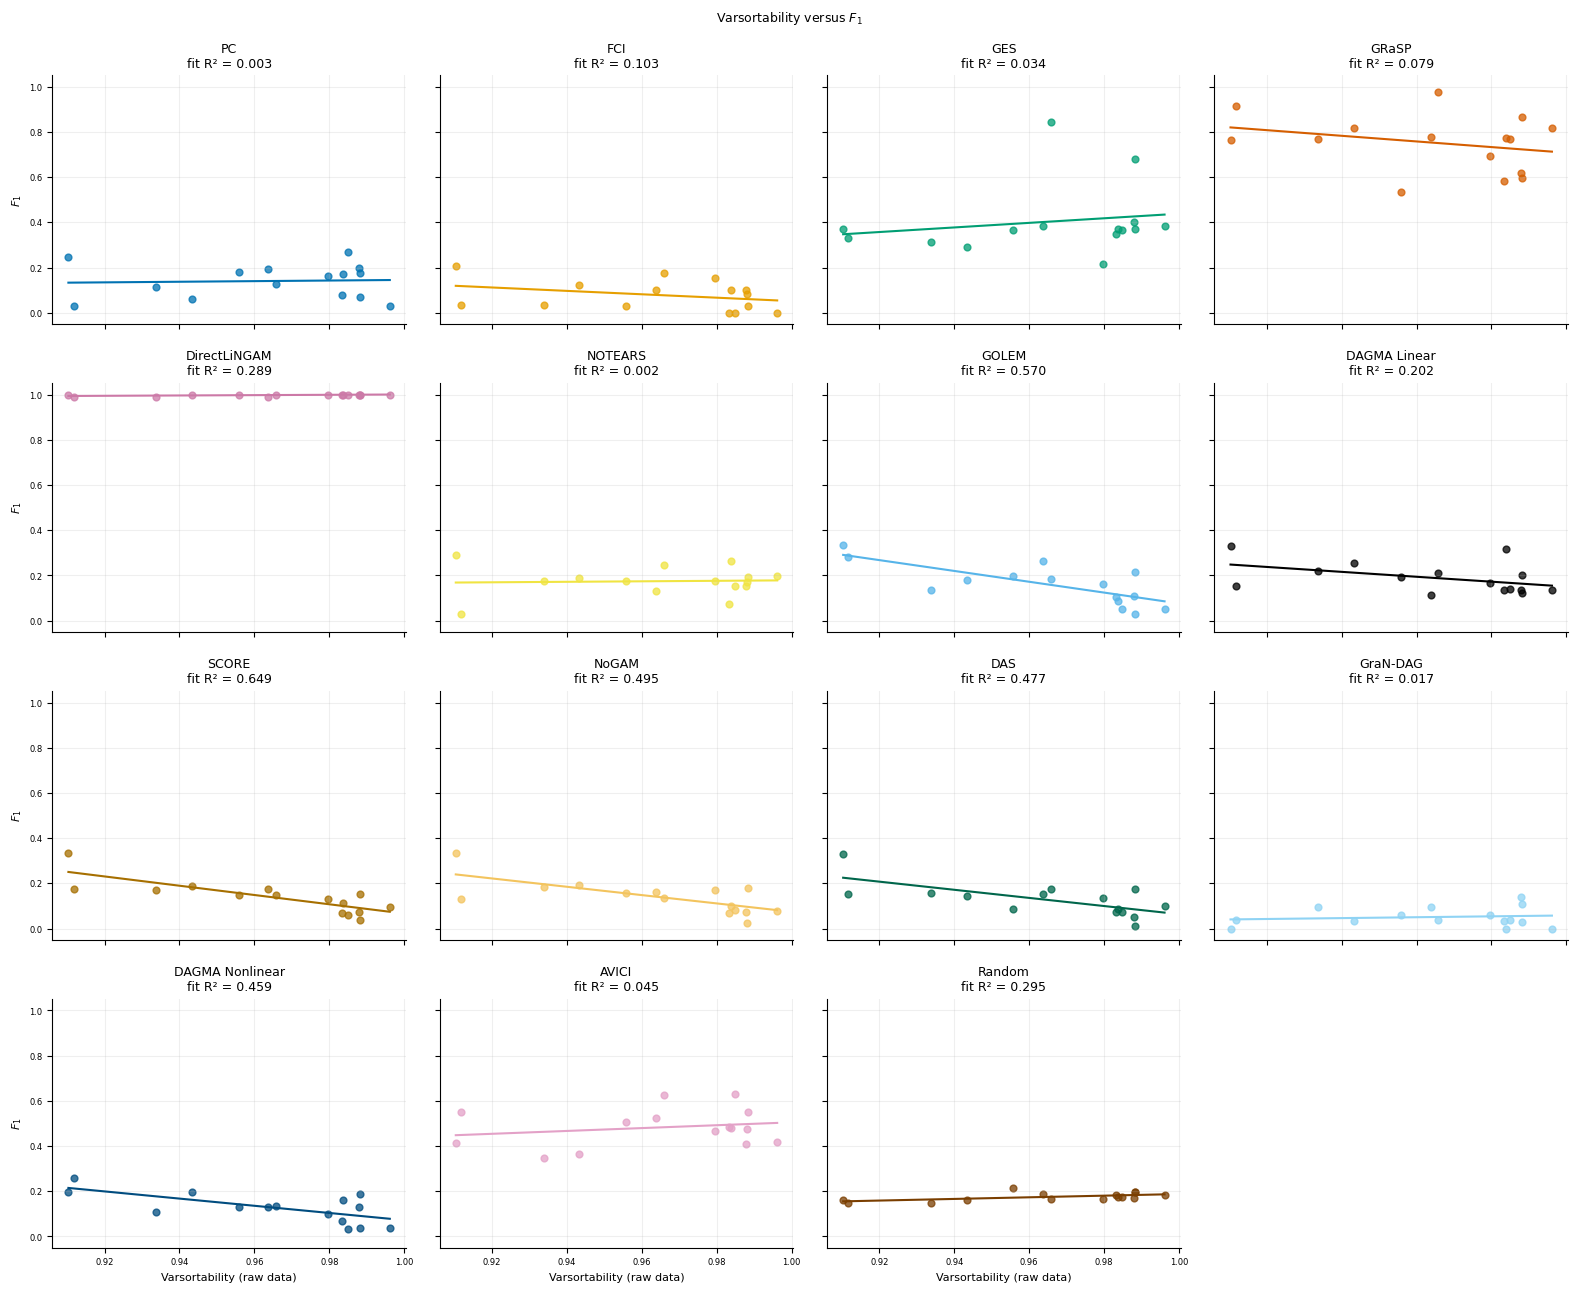

,dataset_seed,dataset,model,metric_value,completed_model_seeds,n_nodes,graph_type,obs_conf,lat_conf,noise,...,sample_path,varsortability,r2_sortability,n_paths,n_ordered_variance_paths,n_tied_variance_paths,n_ordered_r2_paths,n_tied_r2_paths,n_variables,n_observations
0,19,20nodes_EB_obsconf0_latconf0_NonGaussian_Linear,AVICI,0.464286,5,20,EB,0,0,NonGaussian,...,datasets/tuned/20nodes_EB_obsconf0_latconf0_No...,0.979592,0.928571,294,288,0,273,0,20,2000
1,19,20nodes_EB_obsconf0_latconf0_NonGaussian_Linear,DAGMA_Linear,0.166667,5,20,EB,0,0,NonGaussian,...,datasets/tuned/20nodes_EB_obsconf0_latconf0_No...,0.979592,0.928571,294,288,0,273,0,20,2000
2,19,20nodes_EB_obsconf0_latconf0_NonGaussian_Linear,DAGMA_Nonlinear,0.100520,5,20,EB,0,0,NonGaussian,...,datasets/tuned/20nodes_EB_obsconf0_latconf0_No...,0.979592,0.928571,294,288,0,273,0,20,2000
3,19,20nodes_EB_obsconf0_latconf0_NonGaussian_Linear,DAS,0.133333,5,20,EB,0,0,NonGaussian,...,datasets/tuned/20nodes_EB_obsconf0_latconf0_No...,0.979592,0.928571,294,288,0,273,0,20,2000
4,19,20nodes_EB_obsconf0_latconf0_NonGaussian_Linear,DirectLiNGAM,1.000000,5,20,EB,0,0,NonGaussian,...,datasets/tuned/20nodes_EB_obsconf0_latconf0_No...,0.979592,0.928571,294,288,0,273,0,20,2000
5,19,20nodes_EB_obsconf0_latconf0_NonGaussian_Linear,FCI,0.151515,5,20,EB,0,0,NonGaussian,...,datasets/tuned/20nodes_EB_obsconf0_latconf0_No...,0.979592,0.928571,294,288,0,273,0,20,2000
6,19,20nodes_EB_obsconf0_latconf0_NonGaussian_Linear,GES,0.217391,5,20,EB,0,0,NonGaussian,...,datasets/tuned/20nodes_EB_obsconf0_latconf0_No...,0.979592,0.928571,294,288,0,273,0,20,2000
7,19,20nodes_EB_obsconf0_latconf0_NonGaussian_Linear,GOLEM,0.161290,5,20,EB,0,0,NonGaussian,...,datasets/tuned/20nodes_EB_obsconf0_latconf0_No...,0.979592,0.928571,294,288,0,273,0,20,2000
8,19,20nodes_EB_obsconf0_latconf0_NonGaussian_Linear,GRaSP,0.694078,5,20,EB,0,0,NonGaussian,...,datasets/tuned/20nodes_EB_obsconf0_latconf0_No...,0.979592,0.928571,294,288,0,273,0,20,2000
9,19,20nodes_EB_obsconf0_latconf0_NonGaussian_Linear,GraNDAG,0.058824,5,20,EB,0,0,NonGaussian,...,datasets/tuned/20nodes_EB_obsconf0_latconf0_No...,0.979592,0.928571,294,288,0,273,0,20,2000


,dataset,dataset_seed,study,raw_variance_available,sample_path,varsortability,r2_sortability,n_paths,n_ordered_variance_paths,n_tied_variance_paths,n_ordered_r2_paths,n_tied_r2_paths,n_variables,n_observations
0,20nodes_EB_obsconf0_latconf0_NonGaussian_Linear,19,tuned,True,datasets/tuned/20nodes_EB_obsconf0_latconf0_No...,0.979592,0.928571,294,288,0,273,0,20,2000
1,20nodes_EB_obsconf0_latconf0_NonGaussian_Linear,47,tuned,True,datasets/tuned/20nodes_EB_obsconf0_latconf0_No...,0.984906,0.962264,265,261,0,255,0,20,2000
2,20nodes_EB_obsconf0_latconf0_NonGaussian_Linear,50,tuned,True,datasets/tuned/20nodes_EB_obsconf0_latconf0_No...,0.955774,0.867322,407,389,0,353,0,20,2000
3,20nodes_EB_obsconf0_latconf0_NonGaussian_Linear,52,tuned,True,datasets/tuned/20nodes_EB_obsconf0_latconf0_No...,0.988281,0.835938,256,253,0,214,0,20,2000
4,20nodes_EB_obsconf0_latconf0_NonGaussian_Linear,71,tuned,True,datasets/tuned/20nodes_EB_obsconf0_latconf0_No...,0.983264,0.945607,239,235,0,226,0,20,2000
5,20nodes_EB_obsconf0_latconf0_NonGaussian_Linear,75,tuned,True,datasets/tuned/20nodes_EB_obsconf0_latconf0_No...,0.943343,0.892351,353,333,0,315,0,20,2000
6,20nodes_EB_obsconf0_latconf0_NonGaussian_Linear,77,tuned,True,datasets/tuned/20nodes_EB_obsconf0_latconf0_No...,0.933798,0.881533,287,268,0,253,0,20,2000
7,20nodes_EB_obsconf0_latconf0_NonGaussian_Linear,102,tuned,True,datasets/tuned/20nodes_EB_obsconf0_latconf0_No...,0.996139,0.972973,259,258,0,252,0,20,2000
8,20nodes_EB_obsconf0_latconf0_NonGaussian_Linear,125,tuned,True,datasets/tuned/20nodes_EB_obsconf0_latconf0_No...,0.910345,0.586207,145,132,0,85,0,20,2000
9,20nodes_EB_obsconf0_latconf0_NonGaussian_Linear,158,tuned,True,datasets/tuned/20nodes_EB_obsconf0_latconf0_No...,0.963731,0.756477,193,186,0,146,0,20,2000


""


,model,n_datasets,pearson_r,fit_r_squared,slope,intercept,p_value,spearman_rho,spearman_p_value
0,AVICI,15,0.212087,0.044981,0.633163,-0.128491,0.447946,0.139286,0.620546
1,DAGMA_Linear,15,-0.449419,0.201977,-1.087565,1.238137,0.092831,-0.471429,0.076070
2,DAGMA_Nonlinear,15,-0.677602,0.459144,-1.590345,1.662278,0.005509,-0.578571,0.023847
3,DAS,15,-0.690872,0.477304,-1.798150,1.861696,0.004346,-0.535714,0.039567
4,DirectLiNGAM,15,0.538012,0.289457,0.073338,0.927360,0.038567,0.511511,0.051300
5,FCI,15,-0.320715,0.102858,-0.752895,0.804416,0.243826,-0.460444,0.084139
6,GES,15,0.184544,0.034057,1.014265,-0.576058,0.510266,0.471429,0.076070
7,GOLEM,15,-0.754959,0.569962,-2.394685,2.470879,0.001139,-0.671429,0.006128
8,GRaSP,15,-0.280750,0.078821,-1.248711,1.956698,0.310781,-0.021429,0.939578
9,GraNDAG,15,0.130928,0.017142,0.195725,-0.137900,0.641858,0.001794,0.994938


In [3]:
for study, frame in [("tuned", complete)]:
    frame = frame.loc[frame.dataset.eq('20nodes_EB_obsconf0_latconf0_NonGaussian_Linear')].copy()
    values = sortability(frame, study)
    arms = (
        [("untuned", frame)]
        if study == "benchmark"
        else list(frame.groupby("arm", observed=True))
    )
    for arm, arm_frame in arms:
        for family, group in arm_frame.groupby("dataset", observed=True):
            family_output = output / study / "by_family" / family / arm
            family_output.mkdir(parents=True, exist_ok=True)
            data = th.visualization_data(group)
            # F1 and SHD, precision and recall retain dataset-level blocks.
            for metric in ("f1", "SHD", "precision", "recall"):
                blocks = (
                    group.loc[group.finished]
                    .groupby(["dataset_seed", "model"])[metric]
                    .mean()
                    .reset_index()
                )
                summary = (
                    blocks.groupby("model")[metric].agg(["mean", "std", "size"]).reset_index()
                )
                display(summary.head(20))
            for metric in ("f1", "SHD"):
                fig, _, _ = fv.plot_metric_boxplot_grid(
                    data,
                    [{"title": family, "datasets": family}],
                    metric=metric,
                    coverage_policy="all",
                    ncols=1,
                    figsize=(10, 7),
                    font_size=9,
                )
                fig.savefig(family_output / f"{metric}.pdf", bbox_inches="tight")
                display(fig)
                plt.close(fig)
            # Stability only from recorded fits; invariant models remain zero.
            ok = group.loc[group.finished]
            model_range = (
                ok.groupby(["dataset_seed", "model"])
                .f1.agg(lambda v: v.max() - v.min())
                .rename("f1_range")
                .reset_index()
            )
            dataset_range = (
                ok.groupby(["model_seed", "model"])
                .f1.agg(lambda v: v.max() - v.min())
                .rename("f1_range")
                .reset_index()
            )
            for kind, table in [
                ("model_seed", model_range),
                ("dataset_seed", dataset_range),
            ]:
                display(table.head(20))
                summary = table.groupby("model").f1_range.mean().sort_values()
                fig, ax = plt.subplots(figsize=(8, 6))
                summary.rename(index=th.model_label).plot.barh(ax=ax)
                ax.set(
                    xlabel="Mean F1 range",
                    ylabel="",
                    title=f"{family}: {kind.replace('_', ' ')} variability",
                )
                fig.tight_layout()
                fig.savefig(family_output / f"{kind}_stability.pdf")
                display(fig)
                plt.close(fig)
            v = values.loc[values.dataset.eq(family)]
            for score in ("r2_sortability", "varsortability"):
                if v[score].notna().sum() < 3:
                    continue
                fig, _, details = fv.plot_varsortability_vs_f1(
                    data,
                    metric="f1",
                    datasets=family,
                    varsortability_values=v,
                    sortability=score,
                    coverage_policy="all",
                    columns=4,
                    include_r2_sort_regress=False,
                    obs_conf=None,
                    lat_conf=None,
                    font_size=8,
                    title_size=9,
                )
                fig.savefig(family_output / f"{score}.pdf", bbox_inches="tight")
                display(fig)
                plt.close(fig)
                for key, table in details.items():
                    if isinstance(table, pd.DataFrame):
                        display(table.head(20))
                blocks = (
                    ok.groupby(["dataset_seed", "model"])
                    .f1.mean()
                    .reset_index()
                    .merge(v, on="dataset_seed")
                )
                for model, g in blocks.groupby("model"):
                    valid = g[["f1", score]].dropna()
                    constant = valid.nunique().min() < 2
                    r = (
                        None
                        if len(valid) < 3 or constant
                        else spearmanr(valid[score], valid.f1)
                    )
                    correlations.append(
                        dict(
                            study=study,
                            arm=arm,
                            dataset=family,
                            model=model,
                            sortability=score,
                            n_pairs=len(valid),
                            rho=np.nan if r is None else r.statistic,
                            pvalue=np.nan if r is None else r.pvalue,
                            status="constant_or_insufficient" if r is None else "estimated",
                        )
                    )


In [4]:
corr = pd.DataFrame(correlations)
if len(corr):
    from statistical_methods import holm

    corr["pvalue_holm"] = np.nan
    valid = corr.pvalue.notna()
    corr.loc[valid, "pvalue_holm"] = (
        corr.loc[valid]
        .groupby(["study", "arm", "sortability"])
        .pvalue.transform(lambda p: holm(p))
    )
display(corr.head(20))


,study,arm,dataset,model,sortability,n_pairs,rho,pvalue,status,pvalue_holm
0,tuned,tuned,20nodes_EB_obsconf0_latconf0_NonGaussian_Linear,AVICI,r2_sortability,15,-0.117857,0.675712,estimated,1.000000
1,tuned,tuned,20nodes_EB_obsconf0_latconf0_NonGaussian_Linear,DAGMA_Linear,r2_sortability,15,-0.364286,0.181910,estimated,1.000000
2,tuned,tuned,20nodes_EB_obsconf0_latconf0_NonGaussian_Linear,DAGMA_Nonlinear,r2_sortability,15,-0.072442,0.797517,estimated,1.000000
3,tuned,tuned,20nodes_EB_obsconf0_latconf0_NonGaussian_Linear,DAS,r2_sortability,15,-0.713137,0.002839,estimated,0.034067
4,tuned,tuned,20nodes_EB_obsconf0_latconf0_NonGaussian_Linear,DirectLiNGAM,r2_sortability,15,-0.767857,0.000829,estimated,0.011611
5,tuned,tuned,20nodes_EB_obsconf0_latconf0_NonGaussian_Linear,FCI,r2_sortability,15,-0.160714,0.567197,estimated,1.000000
6,tuned,tuned,20nodes_EB_obsconf0_latconf0_NonGaussian_Linear,GES,r2_sortability,15,0.100000,0.722897,estimated,1.000000
7,tuned,tuned,20nodes_EB_obsconf0_latconf0_NonGaussian_Linear,GOLEM,r2_sortability,15,-0.107143,0.703901,estimated,1.000000
8,tuned,tuned,20nodes_EB_obsconf0_latconf0_NonGaussian_Linear,GRaSP,r2_sortability,15,-0.278571,0.314709,estimated,1.000000
9,tuned,tuned,20nodes_EB_obsconf0_latconf0_NonGaussian_Linear,GraNDAG,r2_sortability,15,-0.296429,0.283355,estimated,1.000000
